In [1]:
from google.colab import files
uploaded = files.upload()

Saving diabetic_data.csv to diabetic_data.csv


In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

In [3]:
df = pd.read_csv("diabetic_data.csv", dtype=str, keep_default_na=False)

In [4]:
inc = df[~df["discharge_disposition_id"].astype(int).isin([11, 19, 20, 21, 13, 14])].copy()
inc["readmit_30"] = (inc["readmitted"] == "<30").astype(int)

num = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
       "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
for c in num:
    inc[c] = inc[c].astype(int)

print("Included encounters:", len(inc))
print("Readmissions:", inc["readmit_30"].sum())
print("Rate %:", round(inc["readmit_30"].mean() * 100, 2))

Included encounters: 99343
Readmissions: 11314
Rate %: 11.39


## Summary statistics

In [5]:
summary = inc[num].describe(percentiles=[.25, .5, .75, .99]).T
summary["skew"] = inc[num].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,99%,max,skew
time_in_hospital,99343.0,4.38,2.97,1.0,2.0,4.0,6.0,14.0,14.0,1.14
num_lab_procedures,99343.0,42.91,19.61,1.0,31.0,44.0,57.0,84.0,132.0,-0.24
num_procedures,99343.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0,6.0,1.32
num_medications,99343.0,15.98,8.09,1.0,10.0,15.0,20.0,43.0,81.0,1.34
number_outpatient,99343.0,0.37,1.27,0.0,0.0,0.0,0.0,5.0,42.0,8.84
number_emergency,99343.0,0.20,0.94,0.0,0.0,0.0,0.0,3.0,76.0,22.85
number_inpatient,99343.0,0.63,1.26,0.0,0.0,0.0,1.0,6.0,21.0,3.63
number_diagnoses,99343.0,7.40,1.94,1.0,6.0,8.0,9.0,9.0,16.0,-0.86


### Outliers

In [6]:
q1, q3 = inc[num].quantile(.25), inc[num].quantile(.75)
iqr = q3 - q1
outliers = {c: int(((inc[c] > q3[c] + 1.5 * iqr[c]) | (inc[c] < q1[c] - 1.5 * iqr[c])).sum()) for c in num}
pd.Series(outliers, name="IQR outliers")

,IQR outliers
time_in_hospital,2147
num_lab_procedures,120
num_procedures,4801
num_medications,2455
number_outpatient,16349
number_emergency,11094
number_inpatient,6814
number_diagnoses,277


### Missing values

diag_2                0.4
diag_3                1.4
race                  2.2
payer_code           39.7
medical_specialty    48.9
weight               96.9
dtype: float64


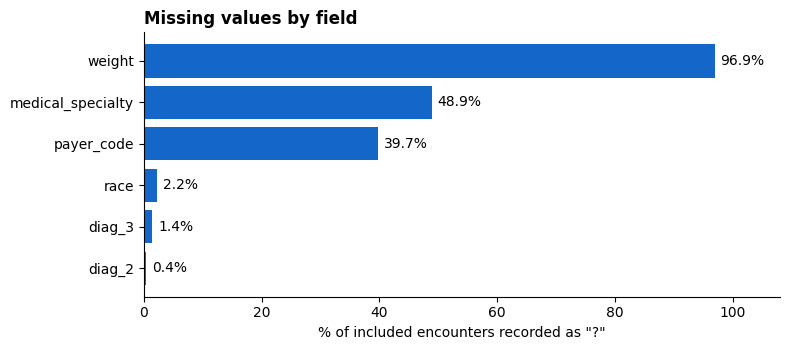

In [7]:
missing = {c: round((inc[c] == "?").mean() * 100, 1)
           for c in ["weight", "medical_specialty", "payer_code", "race", "diag_3", "diag_2"]}
missing = pd.Series(missing).sort_values()
print(missing)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(missing.index, missing.values, color="#1466C8")
for i, v in enumerate(missing.values):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, 108)
ax.set_xlabel('% of included encounters recorded as "?"')
ax.set_title("Missing values by field", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("eda_missingness.png", dpi=150)
plt.show()

### Correlation with readmission

num_procedures       -0.00
num_lab_procedures    0.02
number_outpatient     0.03
num_medications       0.05
number_diagnoses      0.05
time_in_hospital      0.05
number_emergency      0.06
number_inpatient      0.14
Name: readmit_30, dtype: float64


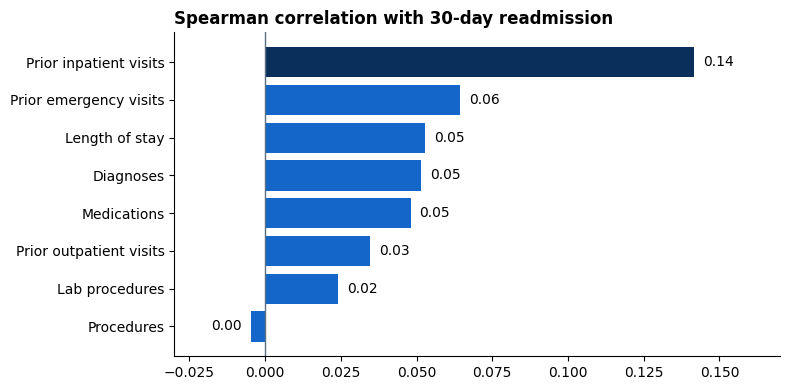

In [8]:
labels = {"time_in_hospital": "Length of stay", "num_lab_procedures": "Lab procedures",
          "num_procedures": "Procedures", "num_medications": "Medications",
          "number_outpatient": "Prior outpatient visits", "number_emergency": "Prior emergency visits",
          "number_inpatient": "Prior inpatient visits", "number_diagnoses": "Diagnoses"}

corr = inc[num + ["readmit_30"]].corr(method="spearman")["readmit_30"].drop("readmit_30").sort_values()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
colours = ["#0B2F5B" if k == "number_inpatient" else "#1466C8" for k in corr.index]
ax.barh([labels[k] for k in corr.index], corr.values, color=colours)
for i, v in enumerate(corr.values):
    ax.text(v + 0.003 if v >= 0 else v - 0.003, i, f"{abs(v):.2f}" if abs(v) < 0.005 else f"{v:.2f}",
            va="center", ha="left" if v >= 0 else "right")
ax.axvline(0, color="#5A6E84", linewidth=1)
ax.set_xlim(-0.03, 0.17)
ax.set_title("Spearman correlation with 30-day readmission", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("eda_correlation_outcome.png", dpi=150)
plt.show()

### Correlation between the numeric fields (heatmap)

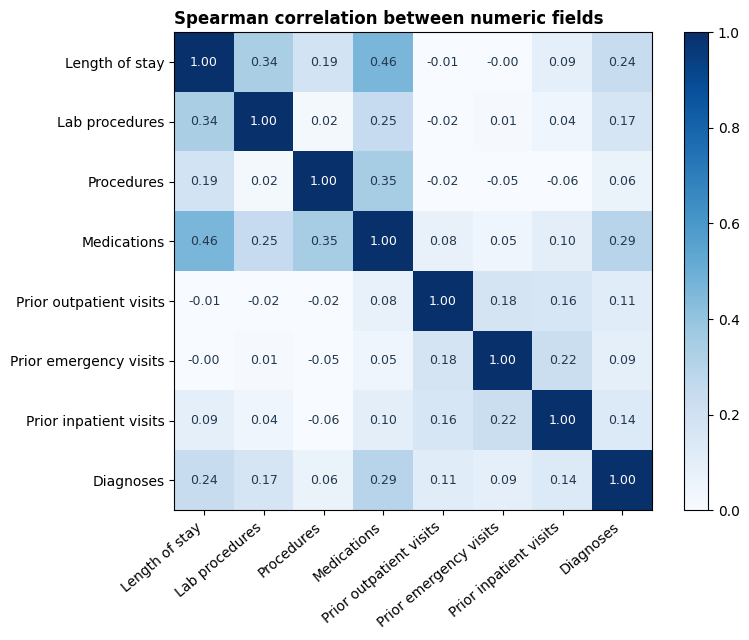

In [9]:
m = inc[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(m.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(num)))
ax.set_yticks(range(len(num)))
ax.set_xticklabels([labels[c] for c in num], rotation=40, ha="right")
ax.set_yticklabels([labels[c] for c in num])
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if m.values[i, j] > 0.5 else "#23384F")
ax.set_title("Spearman correlation between numeric fields", loc="left", fontweight="bold")
fig.colorbar(im, fraction=0.04)
plt.tight_layout()
plt.savefig("eda_correlation_matrix.png", dpi=150)
plt.show()

### Distribution

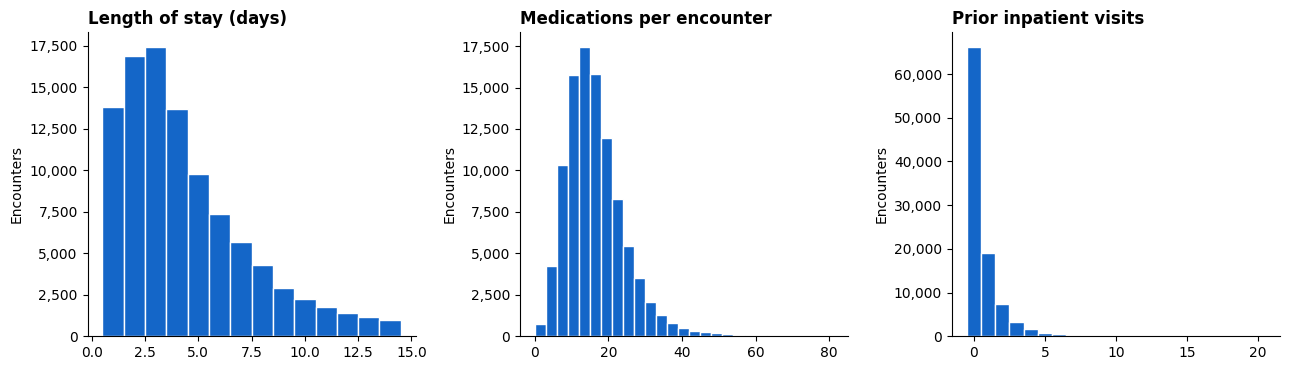

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
charts = [("time_in_hospital", "Length of stay (days)", np.arange(0.5, 15.5, 1)),
          ("num_medications", "Medications per encounter", np.arange(0, 82, 3)),
          ("number_inpatient", "Prior inpatient visits", np.arange(-0.5, 21.5, 1))]
for ax, (col, title, bins) in zip(axes, charts):
    ax.hist(inc[col], bins=bins, color="#1466C8", edgecolor="white")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel("Encounters")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{int(v):,}"))
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150)
plt.show()

### Significance tier test

In [11]:
inc["in_tier"] = (inc["number_inpatient"] >= 2).astype(int)
table = pd.crosstab(inc["in_tier"], inc["readmit_30"])
chi2, p, _, _ = stats.chi2_contingency(table)
print(table)
print("Chi-square:", round(chi2, 1), " p-value:", p)

def rate_ci(k, n):
    r = k / n
    se = np.sqrt(r * (1 - r) / n)
    return round(r * 100, 1), round((r - 1.96 * se) * 100, 1), round((r + 1.96 * se) * 100, 1)

print("Tier rate and 95% CI:", rate_ci(table.loc[1, 1], table.loc[1].sum()))
print("Rest rate and 95% CI:", rate_ci(table.loc[0, 1], table.loc[0].sum()))

readmit_30      0     1
in_tier                
0           77023  8206
1           11006  3108
Chi-square: 1841.5  p-value: 0.0
Tier rate and 95% CI: (np.float64(22.0), np.float64(21.3), np.float64(22.7))
Rest rate and 95% CI: (np.float64(9.6), np.float64(9.4), np.float64(9.8))


### Validations

In [12]:
pid = inc["patient_nbr"].astype(int)
for name, mask in [("Build (70%)", pid % 10 < 7), ("Test (30%)", pid % 10 >= 7)]:
    s = inc[mask]
    tier = s.loc[s["in_tier"] == 1, "readmit_30"].mean()
    rest = s.loc[s["in_tier"] == 0, "readmit_30"].mean()
    capture = s.loc[s["in_tier"] == 1, "readmit_30"].sum() / s["readmit_30"].sum()
    print(f"{name}: tier {tier:.1%}, rest {rest:.1%}, ratio {tier / rest:.2f}, capture {capture:.1%}")

Build (70%): tier 22.8%, rest 9.6%, ratio 2.38, capture 28.3%
Test (30%): tier 20.2%, rest 9.8%, ratio 2.07, capture 25.6%
